# Where Does Public Money Get Stuck? An Audit-Style Analysis of Government Scheme Funds

**Portfolio project · Python · pandas · seaborn · SciPy**
**Dataset:** `govt_fund_utilization.csv` (1,000 fund records, 21 columns: 11 central schemes, 5 ministries, 10 states, 4 financial years from 2021-22 to 2024-25). Amounts are in lakh rupees (1 lakh = 100,000 INR; 100 lakh = 1 crore).

## The problem

Governments sanction money for schemes, release part of it, and then wait for it to be spent and turned into roads, toilets, meals or health services. The ones watching this pipeline (finance and audit teams) need to know **how much of the money is really being used, where it is sitting idle, and which records can't be trusted**. This project works like a small audit analytics unit: it measures the funding pipeline, tests whether any scheme, state or agency explains the gaps, and builds a **Red-Flag Screen** that points reviewers to records worth checking.

> **Read this first:** the file looks synthetic (several columns are almost perfectly uniform; see Q9), so the findings describe *this dataset*, not the real performance of any state or scheme. The value of the project is the workflow, which transfers to real fund-tracking data.

## Summary of findings

1. **The headline utilization figure overstates absorption.** The reported "utilization %" divides spending by the money *released*, not the money *sanctioned*. On the 951 records with spending recorded, projects spent 67.7% of released funds but only **50.3% of sanctioned funds**, because only 74.4% of sanctioned money was ever released.
2. **₹915 crore (32.3% of released money) is sitting unspent.** About 35.8% of it (₹327 crore) sits in 108 projects that have not started, which have received funds but spent nothing.
3. **Utilization is explained by project status and nothing else.** Completed projects average 92.6% utilization, Ongoing 67.1%, Delayed 63.0% and Not Started 0%. No scheme, ministry, state, implementing agency, fund source or financial year differs in utilization (every Kruskal-Wallis p-value is above 0.3).
4. **States differ in project status mix, not in spending.** The mix of Completed, Ongoing, Delayed and Not Started projects differs by state (chi-square p = 0.000); West Bengal stands out with 52.3% of projects Ongoing against 33.0% overall. Differences in idle-money share between states (Rajasthan 26.3% to Uttar Pradesh 40.9%) are within what chance produces.
5. **In-flight projects spend ahead of delivery.** Ongoing projects have spent 15.4 points more of their funds than they have delivered physically, and Delayed ones 11.7 points more, while Completed projects lag by 6.7 points. **166 projects (₹489 crore released) are more than 30 points ahead**, 80 of them more than 50.
6. **Audit remarks cannot be trusted.** They are statistically unrelated to project status (p = 0.514): 91 Completed projects carry a "Delay due to..." remark and 33 Delayed or Not Started projects are marked "Work completed as per schedule". Release dates are also unreliable: only 22.1% fall inside the stated financial year, and 37.0% are two or more years away from it.
7. **The Red-Flag Screen finds 28.6% of records with at least one flag but only 7 with two.** Flag rates do not differ by state or agency (p = 0.894 and 0.798), so the problems look systemic, not concentrated.

## Questions explored

1. How much of the sanctioned money is released and spent? (the funding funnel)
2. How does project status relate to financial and physical progress?
3. Does utilization differ by scheme, ministry, state, agency, fund source or year?
4. Do states differ in their mix of project statuses?
5. Where is money sitting idle?
6. How does financial progress compare with physical progress?
7. Can the audit remarks and release dates be trusted?
8. Which records deserve audit attention? (Red-Flag Screen)
9. Does the data look real or synthetic?

## Reproducibility

Install dependencies with `pip install -r requirements.txt`, place `govt_fund_utilization.csv` in a `data/` folder next to this notebook (or run it on Kaggle with the dataset attached), and run all cells. Charts are written to `images/`. The nodal-officer contact column (names and e-mail addresses) is dropped and never displayed.

## 1. Setup and imports

`pandas` and `numpy` handle the data, `matplotlib` and `seaborn` the charts, and `scipy` the statistical tests. A small `save_fig` helper writes each chart to `images/` for the README.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import display
from scipy import stats

warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['axes.titleweight'] = 'bold'
pd.set_option('display.max_columns', None)
RANDOM_STATE = 42

IMAGES_DIR = Path('images')
IMAGES_DIR.mkdir(exist_ok=True)


def save_fig(fig, filename):
    # Save a Matplotlib figure into images/ at a consistent resolution.
    fig.savefig(IMAGES_DIR / filename, dpi=130, bbox_inches='tight')


NAME = 'govt_fund_utilization.csv'
DATA_PATH = Path('data') / NAME
if not DATA_PATH.exists():
    candidates = [Path(NAME)] + list(Path('/kaggle/input').glob(f'**/{NAME}'))
    candidates = [p for p in candidates if p.exists()]
    if candidates:
        DATA_PATH = candidates[0]
    else:
        raise FileNotFoundError(f'CSV not found. Put {NAME} in data/ or update DATA_PATH.')
print('Reading', DATA_PATH)


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "c:\Users\abhal\anaconda3\Lib\site-packages\ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "c:\Users\abhal\anaconda3\Lib\site-packages\traitlets\config\application.py", line 992, in launch_instance
    app.start()
  File "c:\Users\abhal\anaconda3\Lib\site-packages\ipykernel\kernelapp.py", line 701, in start
    self.io_loop.start()
  File "c:\Users\abhal\anaconda3\Lib\site-packa

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "c:\Users\abhal\anaconda3\Lib\site-packages\ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "c:\Users\abhal\anaconda3\Lib\site-packages\traitlets\config\application.py", line 992, in launch_instance
    app.start()
  File "c:\Users\abhal\anaconda3\Lib\site-packages\ipykernel\kernelapp.py", line 701, in start
    self.io_loop.start()
  File "c:\Users\abhal\anaconda3\Lib\site-packa

AttributeError: _ARRAY_API not found

ImportError: cannot import name 'suppress_pyarrow_values_warning' from 'pandas.io._util' (c:\Users\abhal\anaconda3\Lib\site-packages\pandas\io\_util.py)

**What the code does:** `Path` builds file paths that work on any operating system, `warnings.filterwarnings` hides library notices that don't affect the results, and the loop looks for the CSV in `data/`, the notebook folder and Kaggle's input folder, so the same notebook runs locally and on Kaggle.

## 2. Load the data and inspect its structure

In [ ]:
raw = pd.read_csv(DATA_PATH)
print('Shape:', raw.shape)
display(raw.drop(columns=['Nodal_Officer_Contact']).head())
raw.drop(columns=['Nodal_Officer_Contact']).info()
print('\nExact duplicate rows:', int(raw.duplicated().sum()), '| unique Record_IDs:', raw['Record_ID'].nunique())
print('\nMissing values per column:')
display(raw.isna().sum()[raw.isna().sum() > 0].to_frame('missing'))

Shape: (1000, 21)


,Record_ID,Financial_Year,Date_of_Fund_Release,State,District,Department,Scheme_Name,Scheme_Code,Fund_Source,Implementing_Agency,Sanctioned_Amount_Lakhs,Fund_Released_Lakhs,Fund_Utilized_Lakhs,Utilization_Percent,Physical_Target_Units,Physical_Achievement_Units,Beneficiaries_Target,Beneficiaries_Covered,Status,Audit_Remarks
0,GFU00643,2022-23,2021-08-25,West Bengal,Siliguri,Ministry of Agriculture & Farmers Welfare,PM Kisan Samman Nidhi,PMKISAN,Central Sector,Gram Panchayat,588.66,517.65,212.25,41.00,427,38.0,4138,344.0,Delayed,Awaiting third-party audit clearance
1,GFU00763,2021-22,2023-04-16,Tamil Nadu,Salem,Ministry of Agriculture & Farmers Welfare,Pradhan Mantri Fasal Bima Yojana,PMFBY,Central Sector,State Nodal Agency,88.56,44.61,27.25,61.08,367,104.0,4988,1373.0,Delayed,Material procurement in progress
2,GFU00910,2023-24,2023-01-31,Kerala,Thiruvananthapuram,Ministry of Health & Family Welfare,National Health Mission,NHM,Centrally Sponsored (60:40),District Panchayat / Zilla Parishad,764.59,634.28,NaN,NaN,6,5.0,2151,1621.0,Delayed,Utilization certificate submitted and verified
3,GFU00200,2023-24,2024-08-29,West Bengal,Asansol,Ministry of Education,PM Poshan (Mid-Day Meal Scheme),PMPOSHAN,Centrally Sponsored (60:40),NGO / Partner Organisation,262.37,247.44,147.35,59.55,55,3.0,4122,213.0,Ongoing,Fund utilization certificate pending
4,GFU00587,2021-22,2021-06-21,Karnataka,Belagavi,Ministry of Rural Development,Pradhan Mantri Awas Yojana - Gramin,PMAY-G,Centrally Sponsored (60:40),District Panchayat / Zilla Parishad,731.94,593.82,451.45,76.02,406,337.0,2984,2565.0,Delayed,Fund utilization certificate pending


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Record_ID                   1000 non-null   str    
 1   Financial_Year              1000 non-null   str    
 2   Date_of_Fund_Release        1000 non-null   str    
 3   State                       1000 non-null   str    
 4   District                    1000 non-null   str    
 5   Department                  1000 non-null   str    
 6   Scheme_Name                 1000 non-null   str    
 7   Scheme_Code                 1000 non-null   str    
 8   Fund_Source                 1000 non-null   str    
 9   Implementing_Agency         1000 non-null   str    
 10  Sanctioned_Amount_Lakhs     1000 non-null   float64
 11  Fund_Released_Lakhs         1000 non-null   float64
 12  Fund_Utilized_Lakhs         940 non-null    float64
 13  Utilization_Percent         940 non-null    f

,missing
Fund_Utilized_Lakhs,60
Utilization_Percent,60
Physical_Achievement_Units,25
Beneficiaries_Covered,45
Audit_Remarks,70


**What the code does:** `read_csv` loads the file, `head()` and `info()` show the first rows and each column's type, `duplicated()` counts repeated rows and `isna().sum()` counts blanks. The nodal-officer column is left out of every display because it holds personal names and e-mail addresses.

**What we see:** 1,000 records with a unique ID each and no duplicate rows. Five columns have blanks: the amount utilized and utilization % (60), physical achievement (25), beneficiaries covered (45) and audit remarks (70). Section 3 checks whether the other columns can be trusted.

## 3. Data cleaning and integrity checks (with reasoning)

### 3.1 Inconsistent text in the district column (stray spaces and capitals)

Look for text values with stray spaces or inconsistent capitals, which silently split one category into several.

In [ ]:
text_cols = [c for c in raw.columns if pd.api.types.is_string_dtype(raw[c]) and c != 'Nodal_Officer_Contact']
ws = {c: int((raw[c].dropna() != raw[c].dropna().str.strip()).sum()) for c in text_cols}
display(pd.Series({c: n for c, n in ws.items() if n}).to_frame('rows with stray spaces'))
print('Distinct audit remarks before/after trimming:', raw['Audit_Remarks'].nunique(), '->', raw['Audit_Remarks'].str.strip().nunique())

d = raw.drop(columns=['Nodal_Officer_Contact']).copy()
for c in text_cols:
    d[c] = d[c].str.strip()

not_title = int((d['District'] != d['District'].str.title()).sum())
print(f"District values not capitalised consistently (e.g. '{d.loc[d['District'] != d['District'].str.title(), 'District'].iloc[0]}'): {not_title}")
print('Distinct districts: raw', raw['District'].nunique(), '-> after trimming', d['District'].nunique(),
      '-> after standardising capitals', d['District'].str.title().nunique())
d['District'] = d['District'].str.title()

,rows with stray spaces
District,193
Audit_Remarks,172


Distinct audit remarks before/after trimming: 20 -> 10
District values not capitalised consistently (e.g. 'kozhikode'): 115
Distinct districts: raw 181 -> after trimming 95 -> after standardising capitals 50


**What the code does:** `str.strip()` removes leading and trailing spaces, `str.title()` standardises capitals (`kollam` becomes `Kollam`), and comparing each result with the original counts the rows it changes.

**Finding:** 193 district values and 172 audit remarks carry stray spaces, and 115 district values are not capitalised consistently. Left alone, the 50 real districts would appear as **181** different values and the 10 distinct remarks as 20, which would silently split every group-by. After trimming and standardising capitals they are consistent. (Only the district column needed the capitals fix: the other text columns were already consistent.)

### 3.2 Parse the dates and compare them with the financial year

India's financial year runs from April to March, so a release date can be mapped to its financial year and compared with the `Financial_Year` label on the record.

In [ ]:
d['release_date'] = pd.to_datetime(d['Date_of_Fund_Release'])
d['release_fy'] = np.where(d['release_date'].dt.month >= 4, d['release_date'].dt.year, d['release_date'].dt.year - 1)
d['fy_gap'] = d['release_fy'] - d['Financial_Year'].str[:4].astype(int)

print(f"Release dates run from {d['release_date'].min():%d %b %Y} to {d['release_date'].max():%d %b %Y}")
gap_counts = d['fy_gap'].value_counts().sort_index()
display(gap_counts.to_frame('records').T)
print(f"Release inside the stated financial year : {(d['fy_gap'] == 0).mean():.1%}")
print(f"Within one year of it                    : {(d['fy_gap'].abs() <= 1).mean():.1%}")
print(f"Two or more years away                   : {(d['fy_gap'].abs() >= 2).mean():.1%} ({int((d['fy_gap'].abs() >= 2).sum())} records)")
print(f"FY 2021-22 records released two or more years after the year ended: "
      f"{(d.loc[d['Financial_Year'] == '2021-22', 'fy_gap'] >= 2).mean():.1%}")
print(f"FY 2024-25 records released two or more years before the year began: "
      f"{(d.loc[d['Financial_Year'] == '2024-25', 'fy_gap'] <= -2).mean():.1%}")

Release dates run from 01 Apr 2021 to 27 Mar 2025


fy_gap,-3,-2,-1,0,1,2,3
records,76,144,220,221,189,104,46


Release inside the stated financial year : 22.1%
Within one year of it                    : 63.0%
Two or more years away                   : 37.0% (370 records)
FY 2021-22 records released two or more years after the year ended: 50.6%
FY 2024-25 records released two or more years before the year began: 50.0%


**What the code does:** `pd.to_datetime` converts the text to dates, `np.where` assigns April to December dates to the calendar year and January to March dates to the previous year (the Indian financial year), and the gap column is the release year minus the label year.

**Finding:** Only 22.1% of release dates fall inside the financial year printed on the record, and 37.0% (370 records) are two or more years away. Half of the 2021-22 records were released two or more years after the year ended, and half of the 2024-25 records two or more years before it began, which no real release schedule would produce. The `Financial_Year` label and the release date are therefore **not trustworthy as a pair**, so no trend over financial years is claimed in this project.

### 3.3 Missing values

Is missing data tied to anything? Not-started projects deserve a closer look, since by definition they have spent nothing.

In [ ]:
not_started = d['Status'] == 'Not Started'
value_cols = ['Fund_Utilized_Lakhs', 'Utilization_Percent', 'Physical_Achievement_Units', 'Beneficiaries_Covered']
print('Not Started projects:', int(not_started.sum()))
for c in value_cols:
    recorded = d.loc[not_started & d[c].notna(), c]
    print(f'  {c:30s} recorded: {len(recorded):3d}, all equal to zero: {bool((recorded == 0).all())}, '
          f'missing: {int((not_started & d[c].isna()).sum())}')

display(d.groupby('Status')[value_cols + ['Audit_Remarks']].apply(lambda g: g.isna().mean()).round(2))

# A project that has not started has spent nothing, produced nothing and reached nobody,
# and every recorded Not Started row confirms it, so those blanks are filled with zero.
for c in value_cols:
    d.loc[not_started & d[c].isna(), c] = 0
print('\nMissing after the Not Started rule:')
display(d[value_cols + ['Audit_Remarks']].isna().sum().to_frame('missing'))

Not Started projects: 108
  Fund_Utilized_Lakhs            recorded:  97, all equal to zero: True, missing: 11
  Utilization_Percent            recorded:  97, all equal to zero: True, missing: 11
  Physical_Achievement_Units     recorded: 104, all equal to zero: True, missing: 4
  Beneficiaries_Covered          recorded: 102, all equal to zero: True, missing: 6


,Fund_Utilized_Lakhs,Utilization_Percent,Physical_Achievement_Units,Beneficiaries_Covered,Audit_Remarks
Status,,,,,
Completed,0.05,0.05,0.03,0.03,0.06
Delayed,0.06,0.06,0.01,0.06,0.08
Not Started,0.10,0.10,0.04,0.06,0.07
Ongoing,0.06,0.06,0.02,0.05,0.08



Missing after the Not Started rule:


,missing
Fund_Utilized_Lakhs,49
Utilization_Percent,49
Physical_Achievement_Units,21
Beneficiaries_Covered,39
Audit_Remarks,70


**What the code does:** boolean masks pick out the Not Started rows, `(recorded == 0).all()` checks that every recorded value is zero, and `groupby('Status').apply(...)` shows the share of blanks per status. The loop then sets the missing values of Not Started rows to zero.

**Decision:** All 108 Not Started projects with recorded values show exactly zero spending, output and beneficiaries, so the 11 blank utilization values (and 4 physical and 6 beneficiary values) in that group are filled with zero. That is a rule drawn from the data, not a guess. Blanks in other statuses (49 utilization, 21 physical, 39 beneficiary values) are spread evenly across statuses and are **left missing**: money analyses use the 951 records with a recorded utilization, and a blank is never treated as zero for projects that are running.

### 3.4 Integrity checks: do the numbers agree with each other?

In [ ]:
checks = {
    'Released more than sanctioned': int((d['Fund_Released_Lakhs'] > d['Sanctioned_Amount_Lakhs']).sum()),
    'Utilized more than released': int((d['Fund_Utilized_Lakhs'] > d['Fund_Released_Lakhs']).sum()),
    'Physical achievement above target': int((d['Physical_Achievement_Units'] > d['Physical_Target_Units']).sum()),
    'Beneficiaries covered above target': int((d['Beneficiaries_Covered'] > d['Beneficiaries_Target']).sum()),
    'Districts mapped to more than one state': int((d.groupby('District')['State'].nunique() > 1).sum()),
    'Schemes mapped to more than one ministry': int((d.groupby('Scheme_Name')['Department'].nunique() > 1).sum()),
    'Schemes mapped to more than one fund source': int((d.groupby('Scheme_Name')['Fund_Source'].nunique() > 1).sum()),
}
display(pd.Series(checks).to_frame('records violating the rule'))

recomputed = d['Fund_Utilized_Lakhs'] / d['Fund_Released_Lakhs'] * 100
print('Largest gap between reported Utilization_Percent and utilized / released:',
      round((recomputed - d['Utilization_Percent']).abs().max(), 3))
over = d.loc[d['Beneficiaries_Covered'] > d['Beneficiaries_Target'], 'Beneficiaries_Covered'] / d.loc[d['Beneficiaries_Covered'] > d['Beneficiaries_Target'], 'Beneficiaries_Target']
print(f'Over-coverage is small: the largest is {100 * over.max():.1f}% of target')

,records violating the rule
Released more than sanctioned,0
Utilized more than released,0
Physical achievement above target,0
Beneficiaries covered above target,103
Districts mapped to more than one state,0
Schemes mapped to more than one ministry,0
Schemes mapped to more than one fund source,0


Largest gap between reported Utilization_Percent and utilized / released: 0.005
Over-coverage is small: the largest is 104.1% of target


**What the code does:** each line counts the rows that break a logical rule, and the last lines recompute the utilization percentage from the amounts to see what its denominator is.

**Findings:**

- The money columns are internally consistent: nothing is released above its sanction, nothing is spent above its release, and physical achievement never exceeds its target.
- **`Utilization_Percent` is utilized ÷ released, not utilized ÷ sanctioned** (the recomputed value matches to within 0.005). This matters: the headline figure ignores the money that was sanctioned but never released (Q1).
- 103 records report beneficiaries covered above target, but only up to 104.1% of target, so this is mild over-coverage rather than an error.
- The reference data are clean: every district belongs to one state and every scheme to one ministry and fund source.

### 3.5 Derived measures

New columns put the amounts in crore (1 crore = 100 lakh) and measure progress and idle money.

In [ ]:
d['sanctioned_cr'] = d['Sanctioned_Amount_Lakhs'] / 100
d['released_cr'] = d['Fund_Released_Lakhs'] / 100
d['utilized_cr'] = d['Fund_Utilized_Lakhs'] / 100
d['idle_cr'] = d['released_cr'] - d['utilized_cr']                       # released but not yet spent
d['release_ratio_pct'] = d['released_cr'] / d['sanctioned_cr'] * 100     # how much of the sanction was released
d['absorption_pct'] = d['utilized_cr'] / d['sanctioned_cr'] * 100        # end-to-end: spent / sanctioned
d['physical_pct'] = d['Physical_Achievement_Units'] / d['Physical_Target_Units'] * 100
d['beneficiary_pct'] = d['Beneficiaries_Covered'] / d['Beneficiaries_Target'] * 100
d['spend_minus_delivery'] = d['Utilization_Percent'] - d['physical_pct']  # financial progress minus physical progress

status_order = ['Completed', 'Ongoing', 'Delayed', 'Not Started']
status_colors = {'Completed': '#54A24B', 'Ongoing': '#4C78A8', 'Delayed': '#F2A93B', 'Not Started': '#9E9E9E'}
money = d.dropna(subset=['Fund_Utilized_Lakhs']).copy()      # records with a recorded utilization
print(f'Records with recorded utilization (used for money analyses): {len(money)} of {len(d)}')
display(d[['sanctioned_cr', 'released_cr', 'utilized_cr', 'idle_cr', 'release_ratio_pct', 'absorption_pct',
           'physical_pct', 'spend_minus_delivery']].describe().round(1))

Records with recorded utilization (used for money analyses): 951 of 1000


,sanctioned_cr,released_cr,utilized_cr,idle_cr,release_ratio_pct,absorption_pct,physical_pct,spend_minus_delivery
count,1000.0,1000.0,951.0,951.0,1000.0,951.0,979.0,932.0
mean,4.0,3.0,2.0,1.0,74.7,50.3,62.3,5.2
std,2.3,1.8,1.6,1.3,14.6,25.6,37.7,27.4
min,0.2,0.1,0.0,0.0,50.0,0.0,0.0,-65.9
25%,1.9,1.4,0.6,0.2,62.3,34.8,27.3,-10.0
50%,3.9,2.9,1.7,0.5,74.6,52.7,72.7,-0.6
75%,6.2,4.4,3.1,1.3,88.2,69.5,99.4,17.1
max,8.0,7.8,7.3,7.2,99.9,98.4,100.0,96.0


**What the code does:** the new columns are plain arithmetic on the existing ones: idle money is released minus utilized, **absorption** is utilized over *sanctioned* (the end-to-end measure the reported figure leaves out), and the spend-minus-delivery gap compares financial progress with physical progress. `describe()` summarises each. `status_order` and `status_colors` fix a consistent order and palette for the charts.

## 4. Analysis and the questions

### Q1. How much of the sanctioned money is released and spent?

Follow the money through its three stages on the 951 records with a recorded utilization.

Sanctioned INR 3,806 crore -> released 2,829 crore (74.4%) -> utilized 1,915 crore
Reported-style utilization (utilized / released): 67.7%
End-to-end absorption (utilized / sanctioned)    : 50.3%
Mean of the reported Utilization_Percent column  : 67.5%
Across all 1000 records, 74.5% of sanctioned money was released (release ratio ranges 50% to 100%)


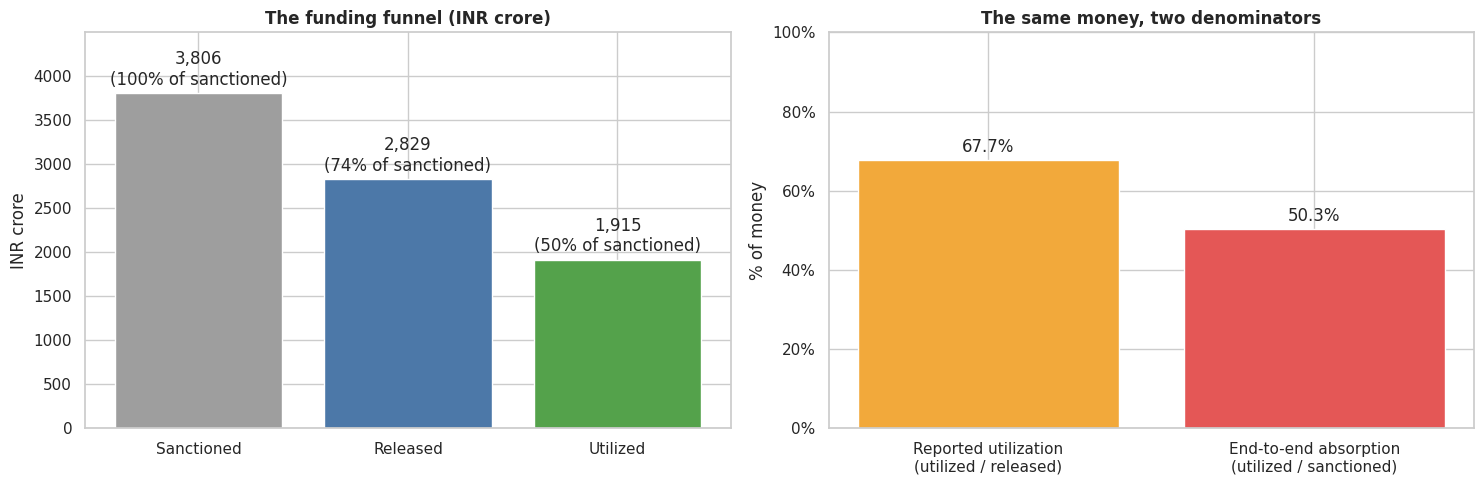

In [ ]:
stages = pd.Series({'Sanctioned': money['sanctioned_cr'].sum(), 'Released': money['released_cr'].sum(),
                    'Utilized': money['utilized_cr'].sum()})
released_share = stages['Released'] / stages['Sanctioned'] * 100
reported = stages['Utilized'] / stages['Released'] * 100
absorption = stages['Utilized'] / stages['Sanctioned'] * 100
print(f"Sanctioned INR {stages['Sanctioned']:,.0f} crore -> released {stages['Released']:,.0f} crore ({released_share:.1f}%) "
      f"-> utilized {stages['Utilized']:,.0f} crore")
print(f'Reported-style utilization (utilized / released): {reported:.1f}%')
print(f'End-to-end absorption (utilized / sanctioned)    : {absorption:.1f}%')
print(f"Mean of the reported Utilization_Percent column  : {money['Utilization_Percent'].mean():.1f}%")
print(f"Across all {len(d)} records, {d['released_cr'].sum() / d['sanctioned_cr'].sum():.1%} of sanctioned money was released "
      f"(release ratio ranges {d['release_ratio_pct'].min():.0f}% to {d['release_ratio_pct'].max():.0f}%)")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
bars = axes[0].bar(stages.index, stages.values, color=['#9E9E9E', '#4C78A8', '#54A24B'])
axes[0].bar_label(bars, labels=[f'{v:,.0f}\n({v / stages["Sanctioned"]:.0%} of sanctioned)' for v in stages.values], padding=3)
axes[0].set(title='The funding funnel (INR crore)', ylabel='INR crore', ylim=(0, stages['Sanctioned'] * 1.18))
ratios = pd.Series({'Reported utilization\n(utilized / released)': reported, 'End-to-end absorption\n(utilized / sanctioned)': absorption})
bars2 = axes[1].bar(ratios.index, ratios.values, color=['#F2A93B', '#E45756'])
axes[1].bar_label(bars2, labels=[f'{v:.1f}%' for v in ratios.values], padding=3)
axes[1].set(title='The same money, two denominators', ylabel='% of money', ylim=(0, 100))
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(100, decimals=0))
plt.tight_layout()
save_fig(fig, '01_funding_funnel.png')
plt.show()

**What the code does:** `sum()` totals each stage in crore, the ratios divide one stage by the other, and `bar_label` writes the values on the bars.

**Reading it:** Of ₹3,806 crore sanctioned on these records, only 74.4% was ever released (₹2,829 crore) and ₹1,915 crore was spent. The reported-style utilization (spent ÷ released) is **67.7%**, but measured against what was sanctioned the absorption is only **50.3%**. Quoting the first number hides the fact that about a quarter of the sanctioned money never left the treasury and half of it has not been spent. The two figures answer different questions (how well released money is used, and how much of the sanction has reached the ground) and should both be reported.

### Q2. How does project status relate to financial and physical progress?

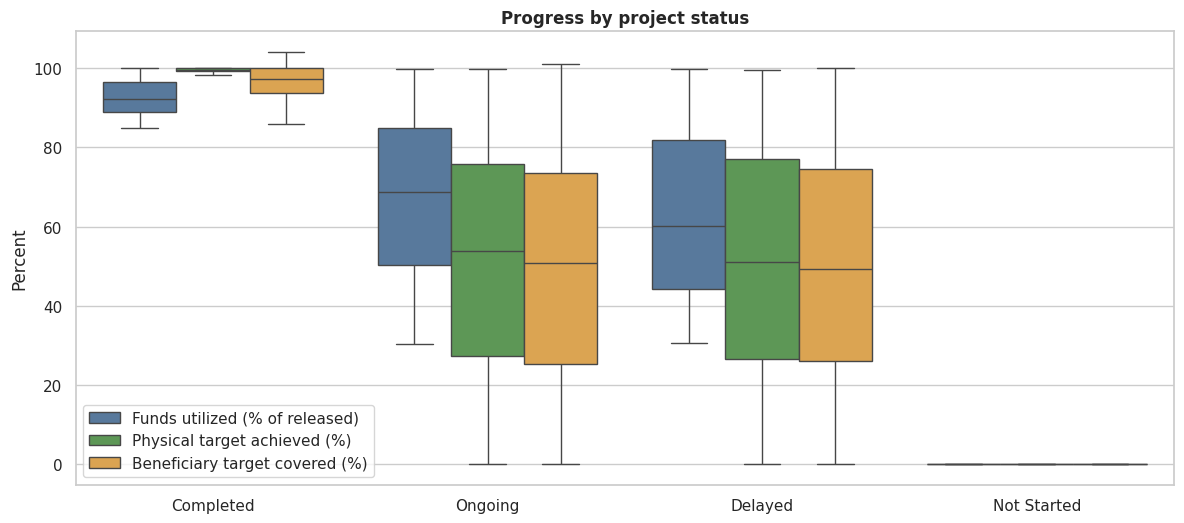

,projects,mean_utilization_pct,mean_physical_pct,mean_beneficiary_pct
Status,,,,
Completed,349,92.6,99.2,96.5
Ongoing,330,67.1,51.6,49.8
Delayed,213,63.0,51.1,49.7
Not Started,108,0.0,0.0,0.0


Correlation, utilization % vs physical %: 0.7
Correlation, physical % vs beneficiary %: 0.997


In [ ]:
progress = d.melt(id_vars='Status', value_vars=['Utilization_Percent', 'physical_pct', 'beneficiary_pct'],
                  var_name='measure', value_name='percent')
progress['measure'] = progress['measure'].map({'Utilization_Percent': 'Funds utilized (% of released)',
                                               'physical_pct': 'Physical target achieved (%)',
                                               'beneficiary_pct': 'Beneficiary target covered (%)'})
fig, ax = plt.subplots(figsize=(12, 5.4))
sns.boxplot(data=progress, x='Status', y='percent', hue='measure', order=status_order,
            palette=['#4C78A8', '#54A24B', '#F2A93B'], showfliers=False, ax=ax)
ax.set(title='Progress by project status', xlabel='', ylabel='Percent')
ax.legend(title='', loc='lower left')
plt.tight_layout()
save_fig(fig, '02_status_vs_progress.png')
plt.show()

summary = d.groupby('Status').agg(projects=('Record_ID', 'size'), mean_utilization_pct=('Utilization_Percent', 'mean'),
                                  mean_physical_pct=('physical_pct', 'mean'),
                                  mean_beneficiary_pct=('beneficiary_pct', 'mean')).reindex(status_order).round(1)
display(summary)
print('Correlation, utilization % vs physical %:', round(d[['Utilization_Percent', 'physical_pct']].corr().iloc[0, 1], 2))
print('Correlation, physical % vs beneficiary %:', round(d[['physical_pct', 'beneficiary_pct']].corr().iloc[0, 1], 3))

**What the code does:** `melt` reshapes three percentage columns into one so a single boxplot can compare them, `groupby('Status').agg(...)` averages each measure per status, and `corr()` measures how closely two columns move together.

**Reading it:** Status lines up with progress exactly as it should. Completed projects average 92.6% utilization and 99.2% physical achievement, Ongoing and Delayed projects sit around 51–52% physical and 63–67% financial, and Not Started projects are at zero. Delayed projects look much like Ongoing ones, so "Delayed" is not visible as lower progress. Physical achievement and beneficiary coverage are almost perfectly correlated (0.997), so the beneficiary column adds almost nothing beyond the physical one. Financial and physical progress are correlated (0.70) but far from identical, which Q6 explores.

### Q3. Does utilization differ by scheme, ministry, state, agency, fund source or year?

Each factor is tested with a Kruskal-Wallis test (a rank test that does not assume a bell-shaped distribution) on the utilization percentage. The test is repeated without Not Started projects, which are all at zero and could mask differences.

,groups,p_all_projects,p_excluding_not_started
factor,,,
Scheme,11,0.842,0.958
Ministry,5,0.654,0.866
State,10,0.323,0.531
Implementing agency,5,0.687,0.523
Fund source,3,0.482,0.488
Financial year,4,0.540,0.245


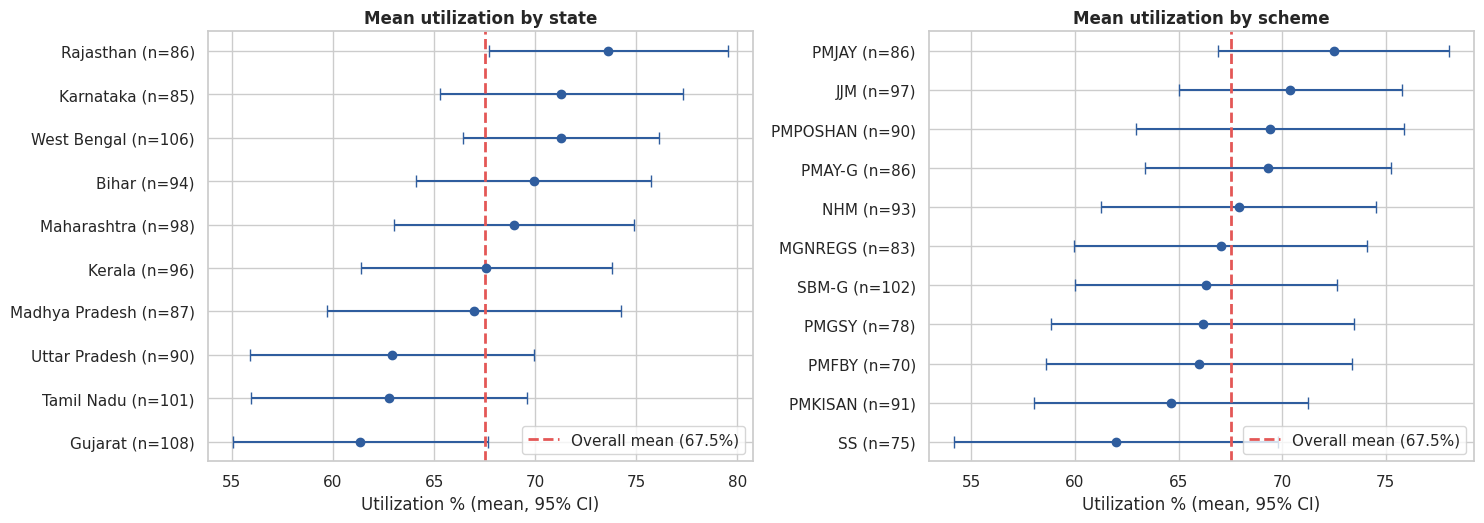

In [ ]:
factors = {'Scheme': 'Scheme_Name', 'Ministry': 'Department', 'State': 'State', 'Implementing agency': 'Implementing_Agency',
           'Fund source': 'Fund_Source', 'Financial year': 'Financial_Year'}
rows = []
for label, col in factors.items():
    all_groups = [g['Utilization_Percent'].values for _, g in money.dropna(subset=['Utilization_Percent']).groupby(col)]
    active = money[(money['Status'] != 'Not Started')].dropna(subset=['Utilization_Percent'])
    active_groups = [g['Utilization_Percent'].values for _, g in active.groupby(col)]
    rows.append({'factor': label, 'groups': len(all_groups),
                 'p_all_projects': stats.kruskal(*all_groups).pvalue,
                 'p_excluding_not_started': stats.kruskal(*active_groups).pvalue})
tests = pd.DataFrame(rows).set_index('factor')
display(tests.round(3))

util = money.dropna(subset=['Utilization_Percent'])
overall = util['Utilization_Percent'].mean()
fig, axes = plt.subplots(1, 2, figsize=(15, 5.4))
for ax, col, title in [(axes[0], 'State', 'Mean utilization by state'), (axes[1], 'Scheme_Code', 'Mean utilization by scheme')]:
    g = util.groupby(col)['Utilization_Percent'].agg(['mean', 'sem', 'size']).sort_values('mean')
    ax.errorbar(g['mean'], range(len(g)), xerr=1.96 * g['sem'], fmt='o', color='#2F5D9E', capsize=4)
    ax.axvline(overall, color='#E45756', linestyle='--', linewidth=2, label=f'Overall mean ({overall:.1f}%)')
    ax.set_yticks(range(len(g)))
    ax.set_yticklabels([f'{i} (n={n})' for i, n in zip(g.index, g['size'])])
    ax.set(title=title, xlabel='Utilization % (mean, 95% CI)')
    ax.legend(loc='lower right')
plt.tight_layout()
save_fig(fig, '03_utilization_by_group.png')
plt.show()

**What the code does:** `stats.kruskal` tests whether several groups come from the same distribution (a small p-value means they differ), `sem` is the standard error of each group's mean, and `1.96 × sem` draws the 95% confidence interval. The dashed line marks the overall mean so differences are easy to see.

**Reading it:** **No factor differs.** Every p-value is above 0.3 (state 0.323, scheme 0.842, ministry 0.654, agency 0.687, fund source 0.482, financial year 0.540), and excluding Not Started projects changes nothing. In the chart every state and scheme interval overlaps the overall mean. In real fund data, scheme design, state capacity and implementing agency usually matter; here none does, which is the first sign the dataset's utilization was assigned by project status alone.

### Q4. Do states differ in their mix of project statuses?

If spending doesn't differ, maybe the *kind* of projects does. A chi-square test checks whether the distribution of statuses is the same across states.

State x status: chi-square = 59.0, dof = 27, p = 0.0004, Cramér's V = 0.14
Largest departures from an even mix (standardised residuals):


standardised_residual
State          Status                            
West Bengal    Ongoing                       3.53
               Not Started                  -2.02
Tamil Nadu     Not Started                   1.94
Madhya Pradesh Delayed                      -1.87
Karnataka      Ongoing                      -1.76

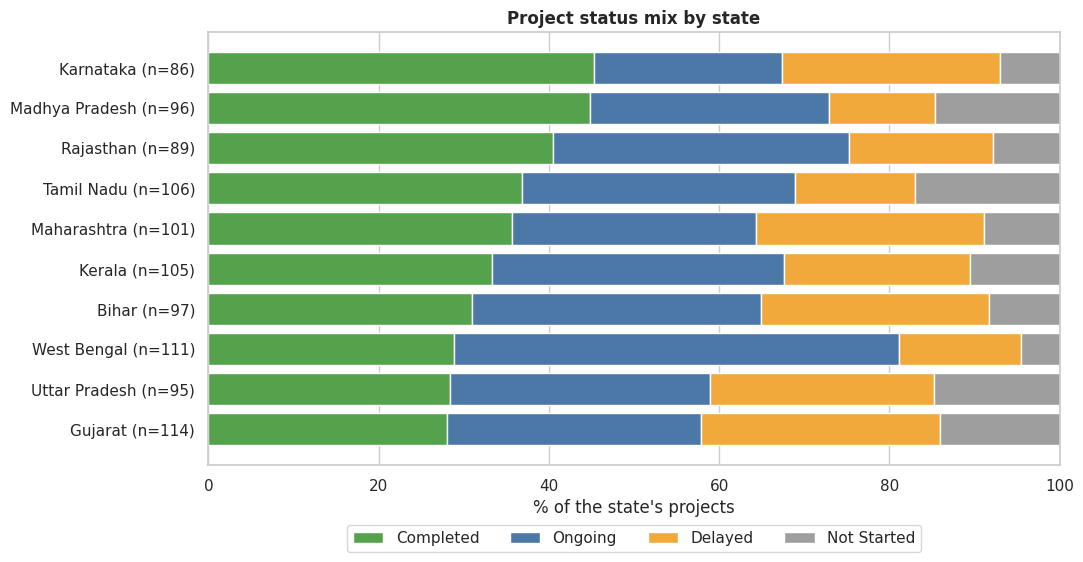

In [ ]:
status_by_state = pd.crosstab(d['State'], d['Status'])
chi2, p, dof, expected = stats.chi2_contingency(status_by_state)
cramers_v = np.sqrt(chi2 / (len(d) * (min(status_by_state.shape) - 1)))
print(f"State x status: chi-square = {chi2:.1f}, dof = {dof}, p = {p:.4f}, Cramér's V = {cramers_v:.2f}")
residuals = ((status_by_state - expected) / np.sqrt(expected)).stack().rename('standardised_residual')
print('Largest departures from an even mix (standardised residuals):')
display(residuals.reindex(residuals.abs().sort_values(ascending=False).index).head(5).round(2).to_frame())

mix = pd.crosstab(d['State'], d['Status'], normalize='index')[status_order] * 100
mix = mix.sort_values('Completed')
fig, ax = plt.subplots(figsize=(11, 5.8))
left = np.zeros(len(mix))
for s in status_order:
    ax.barh(mix.index, mix[s], left=left, color=status_colors[s], label=s)
    left += mix[s].values
ax.set_yticks(range(len(mix)))
ax.set_yticklabels([f'{st} (n={status_by_state.loc[st].sum()})' for st in mix.index])
ax.set(title='Project status mix by state', xlabel='% of the state\'s projects', xlim=(0, 100))
ax.legend(ncol=4, loc='upper center', bbox_to_anchor=(.5, -.12))
plt.tight_layout()
save_fig(fig, '04_status_mix_by_state.png')
plt.show()

**What the code does:** `crosstab` counts projects by state and status, `chi2_contingency` tests whether the mix is the same everywhere and returns the counts expected if it were, and the standardised residual `(observed − expected) / √expected` shows which cells depart most (values beyond about ±2 are notable). Cramér's V rescales the statistic to a 0–1 effect size.

**Reading it:** The status mix **does differ by state** (chi-square 59.0 on 27 degrees of freedom, p = 0.000), though the effect is modest (Cramér's V 0.14). The standout is **West Bengal**: 52.3% of its projects are Ongoing against 33.0% overall (standardised residual 3.53) and only 4.5% have not started. Completed shares run from 28.1% in Gujarat to 45.3% in Karnataka. This is the only structural difference between states in the data. With 10 states and 4 statuses the test has 40 cells, so one strong cell could partly be chance, and these are unweighted records, not a state-level performance ranking.

### Q5. Where is money sitting idle?

**Idle money** is released money not yet spent. It is summed by project status and compared across states, with bootstrap confidence intervals and a permutation test, because individual state shares rest on only about 100 records each.

,projects,released_cr,idle_cr,share_of_all_idle_%
Status,,,,
Completed,333,1004.1,74.8,8.2
Ongoing,310,900.5,292.0,31.9
Delayed,200,597.6,220.8,24.1
Not Started,108,327.3,327.3,35.8


Total idle: INR 915 crore = 32.3% of released funds
Not Started projects: 108 projects hold INR 327 crore with zero spending


State                observed spread 14.6 pts; shuffled 95% range 6.6-18.1; p = 0.163
Scheme_Name          observed spread 12.8 pts; shuffled 95% range 7.1-19.7; p = 0.461
Implementing_Agency  observed spread 6.2 pts; shuffled 95% range 2.5-12.4; p = 0.555


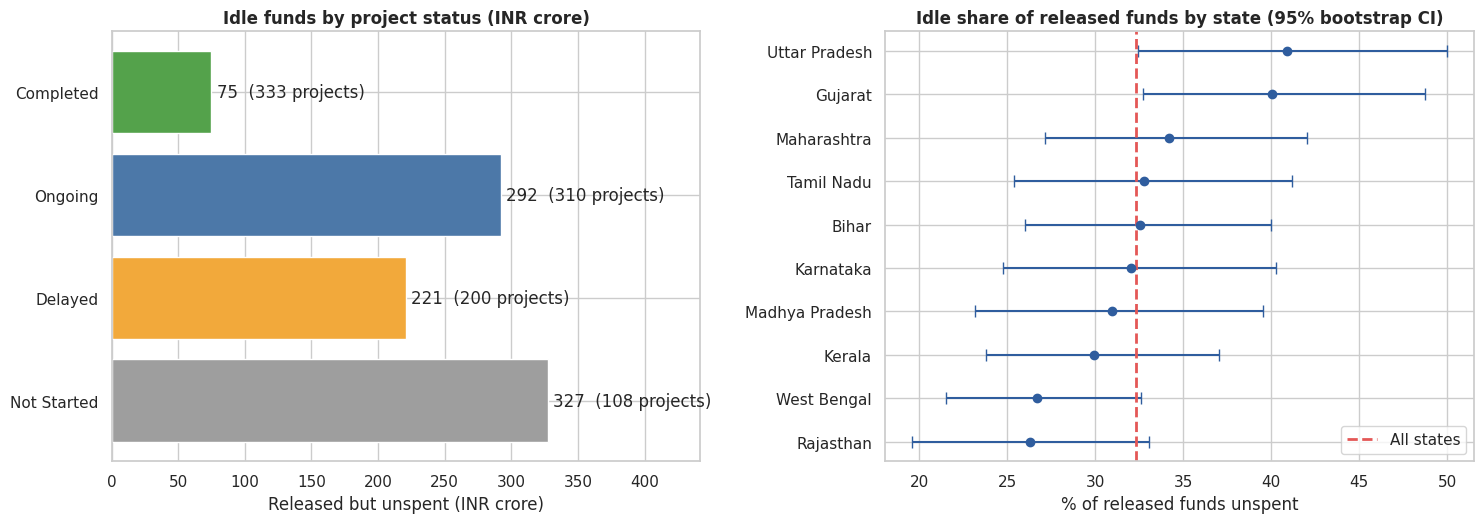

In [ ]:
by_status = (money.groupby('Status').agg(projects=('Record_ID', 'size'), released_cr=('released_cr', 'sum'),
                                         idle_cr=('idle_cr', 'sum')).reindex(status_order))
by_status['share_of_all_idle_%'] = by_status['idle_cr'] / by_status['idle_cr'].sum() * 100
display(by_status.round(1))
print(f"Total idle: INR {money['idle_cr'].sum():,.0f} crore = {money['idle_cr'].sum() / money['released_cr'].sum():.1%} of released funds")
print(f"Not Started projects: {int((money['Status'] == 'Not Started').sum())} projects hold INR "
      f"{money.loc[money['Status'] == 'Not Started', 'idle_cr'].sum():,.0f} crore with zero spending")

# idle share of released funds by state, with bootstrap 95% intervals
rng = np.random.default_rng(RANDOM_STATE)
rows = []
for state, g in money.groupby('State'):
    share = g['idle_cr'].sum() / g['released_cr'].sum()
    boots = []
    for _ in range(1000):
        s = g.iloc[rng.integers(0, len(g), len(g))]
        boots.append(s['idle_cr'].sum() / s['released_cr'].sum())
    rows.append({'state': state, 'records': len(g), 'idle_share': share,
                 'ci_low': np.percentile(boots, 2.5), 'ci_high': np.percentile(boots, 97.5)})
state_idle = pd.DataFrame(rows).sort_values('idle_share')


def share_range(codes, idle, released):
    # spread (highest minus lowest) of the idle share across groups
    s = np.bincount(codes, weights=idle) / np.bincount(codes, weights=released)
    return s.max() - s.min()


results = {}
for col in ['State', 'Scheme_Name', 'Implementing_Agency']:
    codes, _ = pd.factorize(money[col])
    idle, rel = money['idle_cr'].to_numpy(), money['released_cr'].to_numpy()
    observed = share_range(codes, idle, rel)
    shuffled = np.array([share_range(rng.permutation(codes), idle, rel) for _ in range(2000)])
    results[col] = (observed, np.percentile(shuffled, [2.5, 97.5]), (shuffled >= observed).mean())
    print(f"{col:20s} observed spread {100 * observed:.1f} pts; shuffled 95% range "
          f"{100 * results[col][1][0]:.1f}-{100 * results[col][1][1]:.1f}; p = {results[col][2]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.4))
b = by_status.iloc[::-1]
bars = axes[0].barh(b.index, b['idle_cr'], color=[status_colors[s] for s in b.index])
axes[0].bar_label(bars, labels=[f"{v:,.0f}  ({n} projects)" for v, n in zip(b['idle_cr'], b['projects'])], padding=4)
axes[0].set(title='Idle funds by project status (INR crore)', xlabel='Released but unspent (INR crore)', xlim=(0, b['idle_cr'].max() * 1.35))
axes[1].errorbar(100 * state_idle['idle_share'], range(len(state_idle)),
                 xerr=[100 * (state_idle['idle_share'] - state_idle['ci_low']), 100 * (state_idle['ci_high'] - state_idle['idle_share'])],
                 fmt='o', color='#2F5D9E', capsize=4)
axes[1].axvline(100 * money['idle_cr'].sum() / money['released_cr'].sum(), color='#E45756', linestyle='--', linewidth=2, label='All states')
axes[1].set_yticks(range(len(state_idle)))
axes[1].set_yticklabels(state_idle['state'])
axes[1].set(title='Idle share of released funds by state (95% bootstrap CI)', xlabel='% of released funds unspent')
axes[1].legend(loc='lower right')
plt.tight_layout()
save_fig(fig, '05_idle_funds.png')
plt.show()

**What the code does:** `groupby(...).agg(...)` totals released and idle money per group. The **bootstrap** resamples each state's records with replacement 1,000 times to see how much its idle share would wobble by chance; the 2.5th and 97.5th percentiles form the 95% interval. The **permutation test** shuffles the state labels 2,000 times (which destroys any real state effect while keeping group sizes) and asks how often the shuffled spread between the highest and lowest state is as large as the real one.

**Reading it:** ₹915 crore, or 32.3% of released money, is unspent. **35.8% of it (₹327 crore) sits in 108 projects that have not started**, 31.9% in Ongoing projects, 24.1% in Delayed projects and only 8.2% in Completed ones (which is leftover money on finished work). The first call for a monitoring team is therefore the **not-started projects holding released funds**. By state, the idle share runs from 26.3% (Rajasthan) to 40.9% (Uttar Pradesh), a spread of 14.6 points, but the intervals overlap widely and shuffling the state labels produces a spread this large about one time in six (p ≈ 0.16), so it is **not strong evidence** that any state is worse. The same test for schemes and agencies is clearly null.

### Q6. How does financial progress compare with physical progress?

A healthy project spends money roughly in step with what it builds. A project that has spent far more than it has delivered is the classic audit worry (advance payments, inflated bills or simply a missing measurement).

,count,mean,median
Status,,,
Completed,323,-6.7,-7.1
Ongoing,304,15.4,15.2
Delayed,197,11.7,12.8
Not Started,108,0.0,0.0


Records with both measures: 932
Spending more than 30 points ahead of delivery: 166 projects, INR 489 crore released
Spending more than 50 points ahead of delivery: 80 projects, INR 206 crore released
Of the >30-point group: {'Ongoing': 105, 'Delayed': 61}


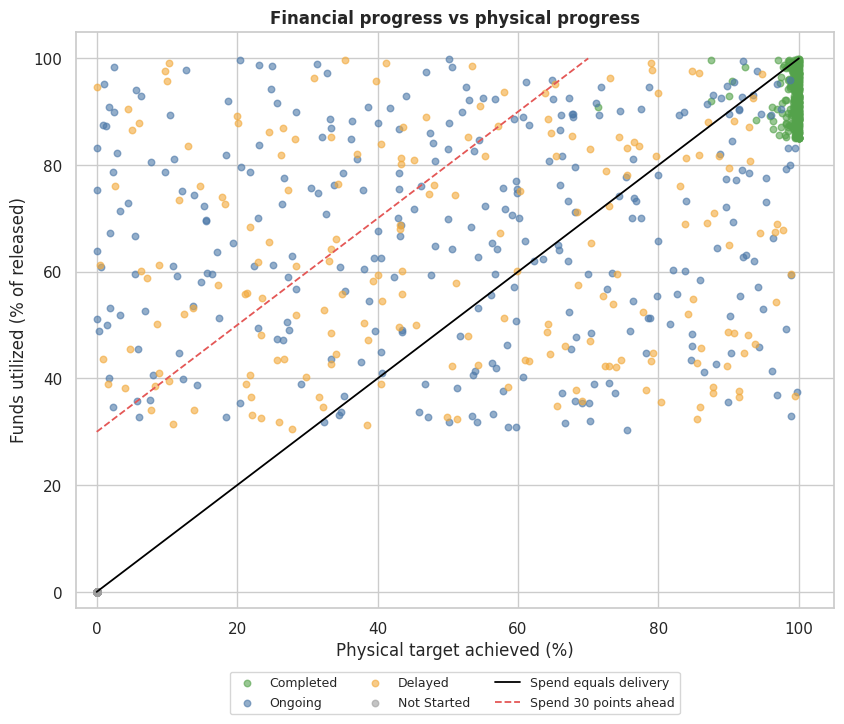

In [ ]:
both = d.dropna(subset=['Utilization_Percent', 'physical_pct'])
gap_by_status = both.groupby('Status')['spend_minus_delivery'].agg(['count', 'mean', 'median']).reindex(status_order).round(1)
display(gap_by_status)
ahead30 = both['spend_minus_delivery'] > 30
ahead50 = both['spend_minus_delivery'] > 50
print(f'Records with both measures: {len(both)}')
print(f"Spending more than 30 points ahead of delivery: {int(ahead30.sum())} projects, INR {both.loc[ahead30, 'released_cr'].sum():,.0f} crore released")
print(f"Spending more than 50 points ahead of delivery: {int(ahead50.sum())} projects, INR {both.loc[ahead50, 'released_cr'].sum():,.0f} crore released")
print('Of the >30-point group:', both.loc[ahead30, 'Status'].value_counts().to_dict())

fig, ax = plt.subplots(figsize=(8.6, 7.4))
for s in status_order:
    sub = both[both['Status'] == s]
    ax.scatter(sub['physical_pct'], sub['Utilization_Percent'], s=22, alpha=.6, color=status_colors[s], label=s)
ax.plot([0, 100], [0, 100], color='black', linewidth=1.3, label='Spend equals delivery')
ax.plot([0, 70], [30, 100], color='#E45756', linewidth=1.3, linestyle='--', label='Spend 30 points ahead')
ax.set(title='Financial progress vs physical progress', xlabel='Physical target achieved (%)', ylabel='Funds utilized (% of released)',
       xlim=(-3, 105), ylim=(-3, 105))
ax.legend(loc='upper center', bbox_to_anchor=(.5, -.1), ncol=3, fontsize=9)
plt.tight_layout()
save_fig(fig, '06_spend_vs_delivery.png')
plt.show()

**What the code does:** the gap is utilization % minus physical %, so a positive gap means spending is ahead of delivery. `scatter` plots every project; points above the solid diagonal have spent more than they delivered, and points above the dashed line are more than 30 points ahead.

**Reading it:** The sign of the gap depends on status. **Ongoing projects have spent 15.4 points more than they have delivered** and **Delayed ones 11.7 points more**, while Completed projects deliver slightly *more* than they spend (6.7 points behind on spending). Spending running ahead of delivery on in-flight work is the pattern the Red-Flag Screen is built to catch: **166 projects (105 Ongoing, 61 Delayed) are more than 30 points ahead, with ₹489 crore released**, and 80 are more than 50 points ahead (₹206 crore). A gap alone is not wrongdoing (advance payments and mobilisation costs are often legitimate), so these are records to look at, not conclusions.

### Q7. Can the audit remarks and release dates be trusted?

If audit remarks were meaningful they would line up with status: "Work completed as per schedule" on Completed projects, "Delay due to..." on Delayed ones. A chi-square test checks whether remarks and status are related at all.

Remark x status: chi-square = 29.1, dof = 30, p = 0.514
Completed projects carrying a 'Delay due to...' remark : 91 (26.1% of Completed)
Delayed projects carrying a 'Delay due to...' remark   : 24.9% of Delayed
'Work completed as per schedule' on Delayed/Not Started : 33 of 98


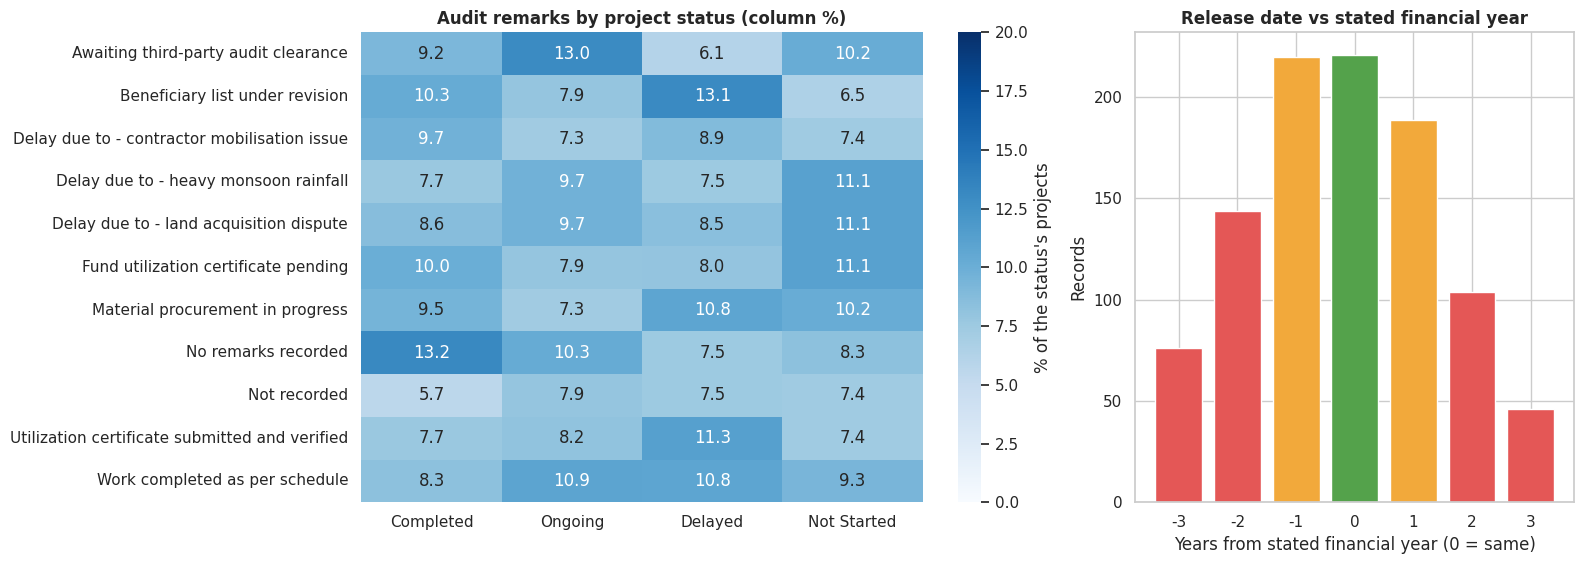

In [ ]:
remark_status = pd.crosstab(d['Audit_Remarks'].fillna('Not recorded'), d['Status'])[status_order]
chi2, p, dof, _ = stats.chi2_contingency(remark_status)
print(f'Remark x status: chi-square = {chi2:.1f}, dof = {dof}, p = {p:.3f}')

delay_remark = d['Audit_Remarks'].str.startswith('Delay due to', na=False)
done_remark = d['Audit_Remarks'] == 'Work completed as per schedule'
print(f"Completed projects carrying a 'Delay due to...' remark : {int((delay_remark & (d['Status'] == 'Completed')).sum())} "
      f"({(delay_remark & (d['Status'] == 'Completed')).sum() / (d['Status'] == 'Completed').sum():.1%} of Completed)")
print(f"Delayed projects carrying a 'Delay due to...' remark   : {(delay_remark & (d['Status'] == 'Delayed')).sum() / (d['Status'] == 'Delayed').sum():.1%} of Delayed")
print(f"'Work completed as per schedule' on Delayed/Not Started : {int((done_remark & d['Status'].isin(['Delayed', 'Not Started'])).sum())} of {int(done_remark.sum())}")

fig, axes = plt.subplots(1, 2, figsize=(16, 5.8), gridspec_kw={'width_ratios': [1.6, 1]})
share = (remark_status / remark_status.sum() * 100).round(1)
sns.heatmap(share, annot=True, fmt='.1f', cmap='Blues', vmin=0, vmax=20, cbar_kws={'label': '% of the status\'s projects'}, ax=axes[0])
axes[0].set(title='Audit remarks by project status (column %)', xlabel='', ylabel='')
fy = d['fy_gap'].value_counts().sort_index()
axes[1].bar(fy.index.astype(str), fy.values, color=['#E45756' if abs(g) >= 2 else ('#54A24B' if g == 0 else '#F2A93B') for g in fy.index])
axes[1].set(title='Release date vs stated financial year', xlabel='Years from stated financial year (0 = same)', ylabel='Records')
plt.tight_layout()
save_fig(fig, '07_audit_remarks_and_dates.png')
plt.show()

**What the code does:** the heatmap shows, for each status, the share of its projects carrying each remark; if remarks were informative the rows would differ, but if they were assigned at random every row would look alike. `str.startswith` finds the "Delay due to..." remarks. The bar chart counts how far each release date is from its stated financial year.

**Reading it:** The remarks are **statistically unrelated to status** (chi-square p = 0.514) and the heatmap is close to uniform. 91 Completed projects (26.1% of them) carry a "Delay due to..." remark, almost the same share as Delayed projects (24.9%), and 33 of the 98 projects marked "Work completed as per schedule" are Delayed or Not Started. 7.0% of records have no remark at all. The release dates fare no better (right panel): only 22.1% fall in the stated year. Neither free-text remarks nor the date/year pair can be used as evidence in this file without verification.

### Q8. Which records deserve audit attention? (Red-Flag Screen)

**Our original feature.** A transparent rule-based screen turns the findings above into a checklist. Each rule is something a reviewer could verify, and a record's **Red-Flag Score** is the number of rules it breaks. Rules that no record breaks are reported too, as checks passed.

,records_flagged
rule,
Spending more than 30 points ahead of physical progress,166
Audit remark contradicts project status,124
Marked Completed but physical achievement below 90%,3
"Marked Not Started but shows spending, output or beneficiaries",0


Records by Red-Flag Score: {0: 714, 1: 279, 2: 7} | at least one flag: 28.6%
Share of flagged records differs by state? chi-square p = 0.894
Share of flagged records differs by scheme? chi-square p = 0.108
Share of flagged records differs by implementing agency? chi-square p = 0.798


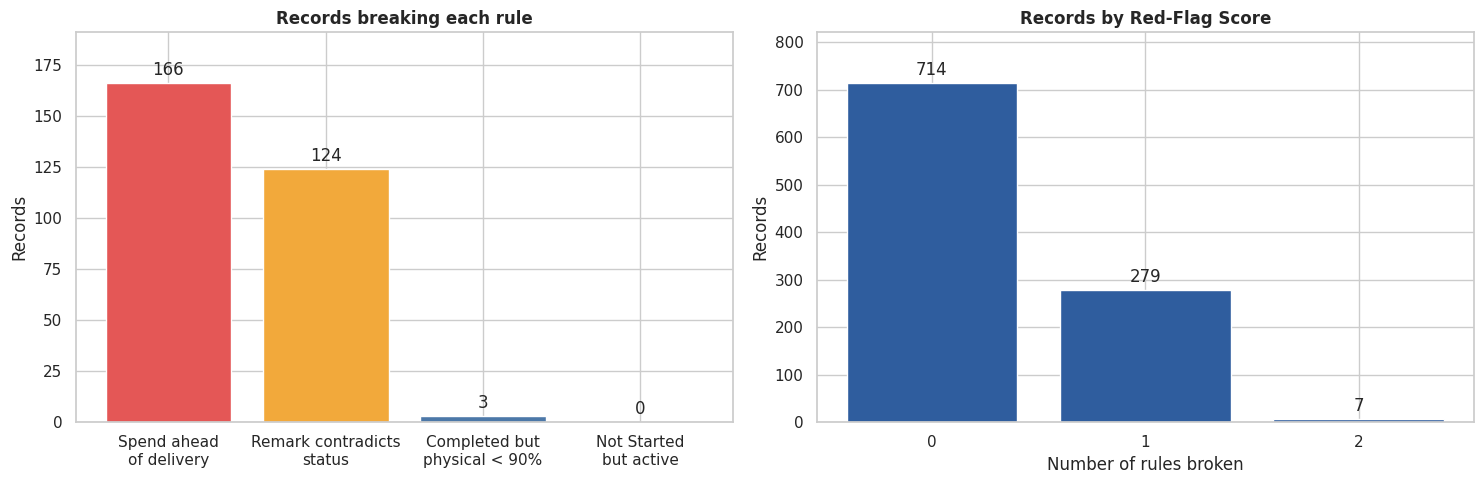


Tier 1: records breaking two or more rules


,Record_ID,State,District,Scheme_Code,Implementing_Agency,Status,released_cr,Utilization_Percent,physical_pct,Audit_Remarks,red_flag_score
627,GFU00926,Tamil Nadu,Chennai,PMAY-G,Gram Panchayat,Completed,5.6,99.6,87.5,Delay due to - contractor mobilisation issue,2
162,GFU00270,Tamil Nadu,Coimbatore,PMJAY,State Nodal Agency,Delayed,5.5,61.2,0.5,Work completed as per schedule,2
657,GFU00518,Gujarat,Ahmedabad,PMGSY,State Nodal Agency,Delayed,3.8,65.6,24.5,Work completed as per schedule,2
492,GFU00523,Karnataka,Mangaluru,PMPOSHAN,Gram Panchayat,Delayed,3.0,73.9,17.9,Work completed as per schedule,2
78,GFU00198,Karnataka,Hubballi,PMGSY,State Nodal Agency,Delayed,2.9,83.6,13.0,Work completed as per schedule,2
786,GFU00436,Gujarat,Rajkot,PMAY-G,Gram Panchayat,Completed,1.5,92.0,87.5,Delay due to - land acquisition dispute,2
344,GFU00107,Kerala,Kollam,MGNREGS,Gram Panchayat,Delayed,0.4,90.4,4.4,Work completed as per schedule,2


Tier 2: the ten largest releases among projects more than 50 points ahead of delivery


,Record_ID,State,District,Scheme_Code,Implementing_Agency,Status,released_cr,Utilization_Percent,physical_pct,Audit_Remarks,red_flag_score
213,GFU00768,Kerala,Kollam,SBM-G,Gram Panchayat,Ongoing,6.3,85.2,32.1,Material procurement in progress,1
67,GFU00313,Tamil Nadu,Coimbatore,JJM,Gram Panchayat,Ongoing,6.0,72.4,15.3,Delay due to - heavy monsoon rainfall,1
974,GFU00475,Madhya Pradesh,Ujjain,PMPOSHAN,Gram Panchayat,Ongoing,5.7,94.3,24.9,Delay due to - contractor mobilisation issue,1
153,GFU00127,West Bengal,Siliguri,JJM,NGO / Partner Organisation,Ongoing,5.5,93.0,6.2,No remarks recorded,1
162,GFU00270,Tamil Nadu,Coimbatore,PMJAY,State Nodal Agency,Delayed,5.5,61.2,0.5,Work completed as per schedule,2
863,GFU00739,Maharashtra,Aurangabad,PMAY-G,Urban Local Body (ULB),Ongoing,5.4,89.9,28.4,NaN,1
594,GFU00203,Tamil Nadu,Madurai,JJM,NGO / Partner Organisation,Ongoing,5.3,74.5,13.8,Work completed as per schedule,1
457,GFU00398,Gujarat,Ahmedabad,MGNREGS,District Panchayat / Zilla Parishad,Ongoing,5.3,81.1,11.0,Work completed as per schedule,1
161,GFU00776,Rajasthan,Jodhpur,JJM,Gram Panchayat,Ongoing,5.3,71.4,3.3,NaN,1
391,GFU00770,Kerala,Kozhikode,SBM-G,District Panchayat / Zilla Parishad,Ongoing,5.3,66.7,5.4,Delay due to - land acquisition dispute,1


In [ ]:
d['flag_spend_ahead'] = d['spend_minus_delivery'] > 30
d['flag_remark_contradicts_status'] = ((done_remark & d['Status'].isin(['Delayed', 'Not Started']))
                                       | (delay_remark & (d['Status'] == 'Completed')))
d['flag_completed_but_incomplete'] = (d['Status'] == 'Completed') & (d['physical_pct'] < 90)
d['flag_not_started_but_active'] = (d['Status'] == 'Not Started') & ((d['Fund_Utilized_Lakhs'] > 0)
                                   | (d['Physical_Achievement_Units'] > 0) | (d['Beneficiaries_Covered'] > 0))
flag_cols = [c for c in d.columns if c.startswith('flag_')]
d['red_flag_score'] = d[flag_cols].sum(axis=1)

rules = pd.DataFrame({
    'rule': ['Spending more than 30 points ahead of physical progress', 'Audit remark contradicts project status',
             'Marked Completed but physical achievement below 90%', 'Marked Not Started but shows spending, output or beneficiaries'],
    'records_flagged': [int(d[c].sum()) for c in flag_cols]})
display(rules.set_index('rule'))
score_counts = d['red_flag_score'].value_counts().sort_index()
print('Records by Red-Flag Score:', score_counts.to_dict(), f"| at least one flag: {(d['red_flag_score'] >= 1).mean():.1%}")
for label, col in [('State', 'State'), ('Scheme', 'Scheme_Name'), ('Implementing agency', 'Implementing_Agency')]:
    p = stats.chi2_contingency(pd.crosstab(d[col], d['red_flag_score'] >= 1))[1]
    print(f'Share of flagged records differs by {label.lower()}? chi-square p = {p:.3f}')

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
short = ['Spend ahead\nof delivery', 'Remark contradicts\nstatus', 'Completed but\nphysical < 90%', 'Not Started\nbut active']
bars = axes[0].bar(short, rules['records_flagged'], color=['#E45756', '#F2A93B', '#4C78A8', '#54A24B'])
axes[0].bar_label(bars, padding=3)
axes[0].set(title='Records breaking each rule', ylabel='Records', ylim=(0, rules['records_flagged'].max() * 1.15))
bars = axes[1].bar(score_counts.index.astype(str), score_counts.values, color='#2F5D9E')
axes[1].bar_label(bars, padding=3)
axes[1].set(title='Records by Red-Flag Score', xlabel='Number of rules broken', ylabel='Records', ylim=(0, score_counts.max() * 1.15))
plt.tight_layout()
save_fig(fig, '08_red_flags.png')
plt.show()

show = ['Record_ID', 'State', 'District', 'Scheme_Code', 'Implementing_Agency', 'Status', 'released_cr', 'Utilization_Percent',
        'physical_pct', 'Audit_Remarks', 'red_flag_score']
print('\nTier 1: records breaking two or more rules')
display(d[d['red_flag_score'] >= 2].sort_values('released_cr', ascending=False)[show].round(1))
print('Tier 2: the ten largest releases among projects more than 50 points ahead of delivery')
display(d[d['spend_minus_delivery'] > 50].sort_values('released_cr', ascending=False)[show].head(10).round(1))

**What the code does:** each `flag_` column is a true/false rule built from comparisons on the existing columns, the score adds them up row by row with `sum(axis=1)`, and the tier tables sort flagged records by the money released so reviewers see the biggest exposures first. Officer contact details are not shown.

**Reading it:** Two rules do the work: **166 records spend more than 30 points ahead of delivery** and **124 have a remark that contradicts their status**. The two checks for impossible states pass cleanly (0 Not Started projects with activity) or nearly so (3 Completed projects with physical achievement under 90%). Of the 1,000 records, 714 have no flag, 279 have one and **only 7 have two**, so Tier 1 is a short list a reviewer can actually work through, and Tier 2 adds the largest spend-ahead cases by money. The share of flagged records does not differ by state (p = 0.894) or implementing agency (p = 0.798) and only weakly by scheme (p = 0.108), so the issues are systemic, not concentrated anywhere. A flag means "check this record", never "this record is wrong".

### Q9. Does the data look real or synthetic?

Real fund data has structure: big schemes dominate the money, release ratios cluster around standard tranches, and states differ in capacity. Randomly generated data looks uniform. Kolmogorov-Smirnov tests compare several columns with a perfectly uniform distribution.

,minimum,maximum,KS_p_vs_uniform
column,,,
Release ratio (released / sanctioned),0.50,0.999,0.662
Sanctioned amount (lakh),20.72,799.870,0.100
Physical target (units),5.00,499.000,0.438
Beneficiary target,50.00,4997.000,0.898


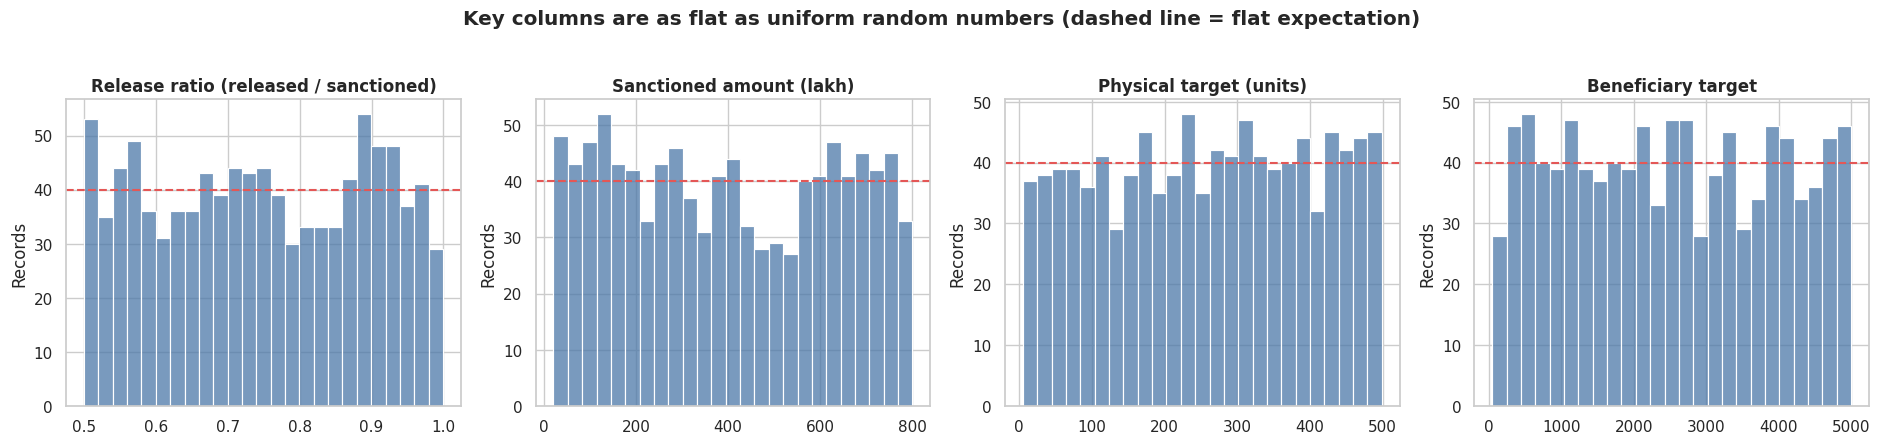

Release dates by calendar year: {2021: 201, 2022: 245, 2023: 219, 2024: 276, 2025: 59}


In [ ]:
uniform_checks = {
    'Release ratio (released / sanctioned)': (d['release_ratio_pct'] / 100, .5, 1.0),
    'Sanctioned amount (lakh)': (d['Sanctioned_Amount_Lakhs'], 20, 800),
    'Physical target (units)': (d['Physical_Target_Units'], 5, 500),
    'Beneficiary target': (d['Beneficiaries_Target'], 50, 5000),
}
rows = []
fig, axes = plt.subplots(1, 4, figsize=(19, 4.3))
for ax, (label, (series, lo, hi)) in zip(axes, uniform_checks.items()):
    ks = stats.kstest((series - lo) / (hi - lo), 'uniform')
    rows.append({'column': label, 'minimum': series.min(), 'maximum': series.max(), 'KS_p_vs_uniform': ks.pvalue})
    sns.histplot(series, bins=25, color='#4C78A8', ax=ax)
    ax.axhline(len(series) / 25, color='#E45756', linestyle='--', linewidth=1.5)
    ax.set(title=label, xlabel='', ylabel='Records')
display(pd.DataFrame(rows).set_index('column').round(3))
plt.suptitle('Key columns are as flat as uniform random numbers (dashed line = flat expectation)', fontweight='bold', y=1.03)
plt.tight_layout()
save_fig(fig, '09_synthetic_fingerprint.png')
plt.show()

print('Release dates by calendar year:', d['release_date'].dt.year.value_counts().sort_index().to_dict())

**What the code does:** `stats.kstest` measures how far a column's distribution is from a perfectly uniform one (a large p-value means it is consistent with uniform), and the dashed line in each histogram shows what a flat distribution would look like.

**Reading it:** All four columns are consistent with uniform random numbers (p = 0.662 for the release ratio, 0.100 for sanctioned amounts, 0.438 for physical targets and 0.898 for beneficiary targets). The release ratio runs from exactly 0.50 to 1.00, sanctions from 20 to 800 lakh and release dates are spread evenly across four years, with the financial-year label unrelated to them. Combined with the near-perfect link between status and utilization and the near-identical physical and beneficiary percentages, it looks simulated. That does **not** invalidate the method (the funnel, the denominator trap, the spend-versus-delivery gap and the Red-Flag Screen apply to real fund data) but it does mean the findings about particular states, schemes or agencies must not be read as facts about reality.

## 5. Conclusion

### Key findings

- **Reported utilization hides the sanctioned-but-unreleased money.** Spending is 67.7% of what was released but only 50.3% of what was sanctioned (Q1, Section 3.4).
- **₹915 crore is released but unspent**, and the largest single pocket (₹327 crore, 35.8%) is in 108 projects that have not started (Q5).
- **Utilization follows project status and nothing else.** No scheme, ministry, state, agency, fund source or year differs (Q3). States differ only in their *mix* of statuses (Q4).
- **In-flight projects spend ahead of delivery**, by 15.4 points for Ongoing and 11.7 points for Delayed projects, with 166 projects more than 30 points ahead (Q6).
- **Audit remarks and release dates are unreliable** and should not be used as evidence without verification (Q7, Section 3.2).
- **A transparent Red-Flag Screen** shortlists records for review: 7 with two flags, 166 with spend-ahead gaps and 124 with contradictory remarks (Q8).

### Practical takeaways for a monitoring team

- Report **both** utilization of released funds and absorption of sanctioned funds.
- Start reviews with **not-started projects holding released money**, then the largest spend-ahead gaps.
- Treat audit remarks as unstructured notes until they are validated against status, and enforce a consistent financial-year field at entry.
- Trim and standardise text fields at data entry: stray spaces and inconsistent capitals alone split 50 real districts into 181 variants.

### Limitations

- **The data look synthetic** (Q9), so no finding describes real schemes, states or agencies.
- Utilization is measured against *released* funds, and the file has no sanction date, release schedule, delay in days or amount at stake in each remark.
- **Blanks** remain for 49 utilization, 21 physical and 39 beneficiary values on running projects; money analyses use the 951 records with a recorded utilization.
- The Red-Flag Screen is rule-based with thresholds (30 points, 90%) chosen by judgement, and a flag is a prompt to review, not proof of a problem.
- With 10 states and about 100 records each, state-level differences are noisy.

### Future improvements

- Run the same workflow on real scheme data (for example the open government data portal at [data.gov.in](https://www.data.gov.in/)) and compare the headline-versus-absorption gap.
- Add sanction and release dates to measure delay in days, and test thresholds for the Red-Flag Screen on records with known audit outcomes.
- Wrap the screen in a small dashboard that lets a reviewer filter by state, scheme or agency.

### Resources used

- [pandas documentation](https://pandas.pydata.org/docs/) · [seaborn gallery](https://seaborn.pydata.org/examples/index.html)
- [SciPy statistics: Kruskal-Wallis, chi-square and KS tests](https://docs.scipy.org/doc/scipy/reference/stats.html)
- [Open Government Data Platform India](https://www.data.gov.in/)

### Data source note

The analysed file is `govt_fund_utilization.csv` (1,000 records, 21 columns). It does not state its provider, version or licence. Before publishing, add the source and check its terms. The nodal-officer column contains names and e-mail addresses (apparently synthetic); it is excluded from this notebook and should not be republished.